# 08.6 · Training well: epochs, batches, learning rate, dropout, early stopping

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/06-training-well/lesson.ipynb)

Read the [README](README.md) first. This notebook runs the experiments behind its tables. Each training run takes a few seconds; the whole notebook a few minutes on a laptop.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import keras
from keras import layers
keras.utils.set_random_seed(42)      # same starting weights every run (small differences across machines are normal)
print("Keras", keras.__version__, "on", keras.backend.backend())

Keras 3.15.1 on tensorflow


In [2]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)            # fit on training customers only (lesson 04.5)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

from sklearn.metrics import roc_auc_score
y_tr = y_train.to_numpy()
X_small, y_small = Xs_train[:300], y_tr[:300]        # a deliberately tiny training set
X_val, y_val = Xs_train[300:], y_tr[300:]            # validation: the other training customers

def small_net(learning_rate=0.001, optimizer=None):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([keras.Input((5,)), layers.Dense(16, activation="relu"),
                          layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=optimizer or keras.optimizers.Adam(learning_rate), loss="binary_crossentropy")
    return m

def big_net(dropout=0.0, l2=0.0, batchnorm=False):
    """Two layers of 256 neurons: far too big for 300 customers, on purpose."""
    keras.utils.set_random_seed(42)
    reg = keras.regularizers.L2(l2) if l2 else None
    stack = [keras.Input((5,))]
    for _ in range(2):
        stack.append(layers.Dense(256, activation="relu", kernel_regularizer=reg))
        if batchnorm: stack.append(layers.BatchNormalization())
        if dropout: stack.append(layers.Dropout(dropout))
    m = keras.Sequential(stack + [layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(0.003), loss="binary_crossentropy")
    return m

def test_auc(m):
    return roc_auc_score(y_test, m.predict(Xs_test, verbose=0).ravel())

3,317 customers, churn rate 43.6%, train 2,487 / test 830


## 1. Momentum by hand

The README table: one weight, steady gradient 1, learning rate 0.1, momentum 0.9.

In [3]:
w_sgd, w_mom, u = 0.0, 0.0, 0.0
for step in range(1, 4):
    w_sgd -= 0.1 * 1.0
    u = 0.9 * u - 0.1 * 1.0
    w_mom += u
    print(f"step {step}: SGD w = {w_sgd:.3f}   momentum u = {u:.3f}, w = {w_mom:.3f}")

step 1: SGD w = -0.100   momentum u = -0.100, w = -0.100
step 2: SGD w = -0.200   momentum u = -0.190, w = -0.290
step 3: SGD w = -0.300   momentum u = -0.271, w = -0.561


## 2. Learning rate

Same 5-16-1 network, Adam, 30 epochs, five learning rates.

In [4]:
lr_curves = {}
for lr in [1.0, 0.1, 0.01, 0.001, 0.0001]:
    h = small_net(lr).fit(Xs_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)
    lr_curves[lr] = h.history["loss"]
    print(f"lr {lr:<7}: training loss epoch 1 / 10 / 30 = "
          f"{h.history['loss'][0]:.3f} / {h.history['loss'][9]:.3f} / {h.history['loss'][29]:.3f}"
          f"   best validation loss {min(h.history['val_loss']):.3f}")

lr 1.0    : training loss epoch 1 / 10 / 30 = 2.400 / 0.673 / 0.689   best validation loss 0.936


lr 0.1    : training loss epoch 1 / 10 / 30 = 0.617 / 0.587 / 0.596   best validation loss 0.588


lr 0.01   : training loss epoch 1 / 10 / 30 = 0.611 / 0.575 / 0.569   best validation loss 0.589


lr 0.001  : training loss epoch 1 / 10 / 30 = 0.691 / 0.582 / 0.574   best validation loss 0.594


lr 0.0001 : training loss epoch 1 / 10 / 30 = 0.720 / 0.665 / 0.610   best validation loss 0.609


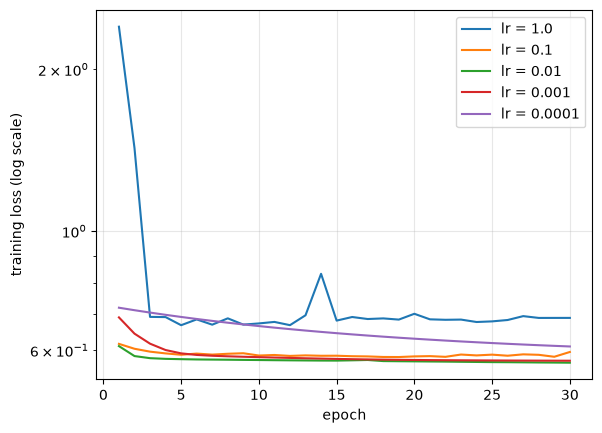

In [5]:
for lr, curve in lr_curves.items():
    plt.plot(range(1, 31), curve, label=f"lr = {lr}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("training loss (log scale)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 3. Optimisers

Learning rate 0.01 for all three.

In [6]:
for name, opt in [("SGD", keras.optimizers.SGD(0.01)),
                  ("SGD + momentum", keras.optimizers.SGD(0.01, momentum=0.9)),
                  ("Adam", keras.optimizers.Adam(0.01))]:
    h = small_net(optimizer=opt).fit(Xs_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)
    print(f"{name:15s} training loss epoch 1 / 5 / 30: "
          f"{h.history['loss'][0]:.3f} / {h.history['loss'][4]:.3f} / {h.history['loss'][29]:.3f}")

SGD             training loss epoch 1 / 5 / 30: 0.705 / 0.628 / 0.585


SGD + momentum  training loss epoch 1 / 5 / 30: 0.647 / 0.583 / 0.575


Adam            training loss epoch 1 / 5 / 30: 0.611 / 0.578 / 0.569


## 4. Overfitting on purpose

300 training customers, a network with tens of thousands of weights, 200 epochs. We validate on the other 2,187 *training* customers. The test customers are only scored at the very end.

67,585 parameters for 300 customers


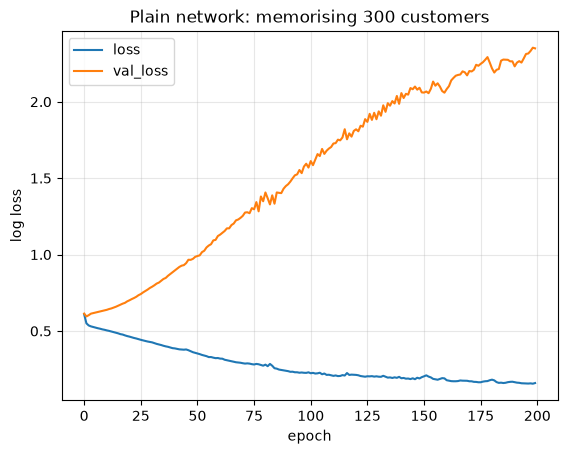

In [7]:
plain = big_net()
print(f"{plain.count_params():,} parameters for {len(X_small)} customers")
h_plain = plain.fit(X_small, y_small, epochs=200, batch_size=32, validation_data=(X_val, y_val), verbose=0)
pd.DataFrame(h_plain.history).plot(title="Plain network: memorising 300 customers")
plt.xlabel("epoch"); plt.ylabel("log loss"); plt.grid(alpha=.3); plt.show()

The textbook overfitting picture: training loss keeps falling, validation loss bottoms out within the first few epochs and then climbs.

## 5. Four fixes, compared

In [8]:
results = {}
for name, kwargs in [("plain", {}), ("dropout 0.5", {"dropout": 0.5}),
                     ("L2 0.001", {"l2": 1e-3}), ("batch normalisation", {"batchnorm": True})]:
    m = big_net(**kwargs)
    h = m.fit(X_small, y_small, epochs=200, batch_size=32, validation_data=(X_val, y_val), verbose=0)
    vl = h.history["val_loss"]
    results[name] = [h.history["loss"][-1], min(vl), int(np.argmin(vl)) + 1, vl[-1], test_auc(m)]
print(pd.DataFrame(results, index=["final train loss", "best val loss", "best epoch",
                                   "final val loss", "test AUC"]).T.round(3))

                     final train loss  best val loss  best epoch  \
plain                           0.159          0.595         2.0   
dropout 0.5                     0.433          0.594         4.0   
L2 0.001                        0.389          0.640        15.0   
batch normalisation             0.037          0.613        25.0   

                     final val loss  test AUC  
plain                         2.349     0.652  
dropout 0.5                   1.031     0.684  
L2 0.001                      0.999     0.684  
batch normalisation           1.326     0.711  


## 6. Early stopping

Stop once validation loss has not improved for 10 epochs, and roll back to the best epoch. A checkpoint also saves the best model to `models/`.

In [9]:
models_dir = data_path("download.py").parent.parent / "models"
models_dir.mkdir(exist_ok=True)
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint(models_dir / "churn_early_stopped.keras",
                                             monitor="val_loss", save_best_only=True)]
early = big_net()
h = early.fit(X_small, y_small, epochs=200, batch_size=32, validation_data=(X_val, y_val),
              callbacks=callbacks, verbose=0)
print(f"ran {len(h.history['loss'])} epochs, best epoch {int(np.argmin(h.history['val_loss'])) + 1}, "
      f"test AUC {test_auc(early):.3f}")

ran 12 epochs, best epoch 2, test AUC 0.730


Early stopping beats every other fix here: it keeps the weights from before memorising began.

And the honest comparison: logistic regression on the same 300 customers.

In [10]:
from sklearn.linear_model import LogisticRegression
lr300 = LogisticRegression(max_iter=1000).fit(X_small, y_small)
print(f"logistic regression on 300 customers: test AUC "
      f"{roc_auc_score(y_test, lr300.predict_proba(Xs_test)[:, 1]):.3f}")

logistic regression on 300 customers: test AUC 0.736


Slightly better than the best network (0.736 against 0.730). With little data and few columns, six parameters beat 67,585 carefully restrained ones. Regularisation tools let a big network survive small data; they do not make it better than a model of the right size.

## Quiz answers

1. Overfitting: the network is memorising the training rows. Fixes: early stopping, dropout, L2, more data, a smaller network.
2. Far too large: updates overshoot, the loss jumps or explodes and never settles (lr 1.0 here). Far too small: the loss falls very slowly and training needs many more epochs (lr 0.0001).
3. So that each output's expected value stays the same as without dropout; the next layer then sees the same scale during training and prediction, when dropout is switched off.
4. When training stops, it puts back the weights from the epoch with the best validation score, instead of keeping the last (worse) ones.
5. Stopping when the test score is best uses the test set to make a training decision, so the test score is no longer an honest estimate of performance on new customers (lesson 04.2).

**Next:** [08.7 Images as numbers; convolution by hand](../07-images-and-convolution/)